# PROL: Test Set Validation on Unseen Processes
The LOPO cross validation only leaves out DoE runs. The three `VAL_*` runs were never used for training, early stopping, scaler fitting of the models or architecture selection, and were run with a **different (non-exponential) glucose feed and different start conditions**. Here Std-Hyb (`MPM_144A`) and FBA-Hyb (`MPM_144B`) are applied to them as a true test set.

Each model is the 12-member LOPO ensemble (`set_1..12_last.eqx`), i.e. no model has seen any VAL data.

In [1]:
from pathlib import Path
REPO_ROOT = Path.cwd()
while not (REPO_ROOT / 'MPMs').is_dir() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
import os
os.environ['JAX_PLATFORMS'] = 'cpu'
import importlib
import equinox as eqx
import jax.numpy as jnp
import jax
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import MPMs.DATA_functions_01 as DF
import MPMs.UTIL_functions_01 as UF
import MPMs.ANA_functions_02 as AF
import MPMs.HELPER_functions_02 as HF
import MPMs.MPM_functions_07 as MF

## 1. Load data

In [2]:
base_path = f"{REPO_ROOT}/prol_model_scripts/"
MM = UF.import_module_from_path(f"{base_path}/MPM_144B.py")
scalers, ALL_kwargs = MM.get_model_config(verbose=False)
exp_dataframes = MM.get_exp_dfs()

VAL_names   = ['VAL_R1', 'VAL_R2', 'VAL_R3']
TRAIN_names = HF.get_valid_sets()
TRAIN_names = [n[0] for n in TRAIN_names]

def get_data(names):
    return DF.PRE_process_data(exp_dataframes, scalers, names,
                               inverse=True, yi_method="copy",
                               Ycols=["G","P","X","V_N"],
                               Ucols=["t","T","Cf_N","G_Cf"],
                               verbose=False)
VAL_DATA = get_data(VAL_names)
EXP_DATA = get_data(TRAIN_names)
for n, a in zip(["yy","YT","uc","UT","DS","yi"], VAL_DATA):
    print(n, a.shape)
assert all(bool(jnp.all(jnp.isfinite(a))) for a in VAL_DATA)

yy (3, 7, 4)
YT (3, 7, 1)
uc (3, 4, 1499, 4)
UT (3, 1500, 1)
DS (3, 12, 1)
yi (3, 1, 4)


## 2. Check Input Range

In [3]:
off, onl, dsp = exp_dataframes
def rng(df, cols, names):
    d = df[df.process.isin(names)]
    return {c: (d[c].min(), d[c].max()) for c in cols}
rows = []
for label, df, cols in [("onl", onl, ["T","Cf_N","G_Cf"]), ("off", off, ["G","P","X","V_N"])]:
    tr, va = rng(df, cols, TRAIN_names), rng(df, cols, VAL_names)
    for c in cols:
        out = va[c][0] < tr[c][0] or va[c][1] > tr[c][1]
        rows.append([c, f"{tr[c][0]:.4g} – {tr[c][1]:.4g}", f"{va[c][0]:.4g} – {va[c][1]:.4g}", "OUTSIDE" if out else "inside"])
i0 = off[np.isclose(off.t, 0)]
for c in ["G","P","X","V_N"]:
    tr = i0[i0.process.isin(TRAIN_names)][c]; va = i0[i0.process.isin(VAL_names)][c]
    rows.append([f"{c}(t=0)", f"{tr.min():.4g} – {tr.max():.4g}", f"{va.min():.4g} – {va.max():.4g}",
                 "OUTSIDE" if (va.min()<tr.min() or va.max()>tr.max()) else "inside"])
pd.DataFrame(rows, columns=["variable","DoE (train)","VAL (test)",""]).set_index("variable")

,DoE (train),VAL (test),
variable,,,
T,298.5 – 316.8,303.2 – 313.8,inside
Cf_N,0.001175 – 0.6291,0.0245 – 0.149,inside
G_Cf,359.7 – 369.7,382.1 – 385.7,OUTSIDE
G,0 – 141,0.09067 – 0.3627,inside
P,0 – 9.87,0 – 8.752,inside
X,21.17 – 70.17,30.67 – 63.03,inside
V_N,0.889 – 4.044,1.297 – 2.44,inside
G(t=0),0 – 0.5012,0.09067 – 0.09067,inside
P(t=0),0 – 0,0 – 0,inside


## 3. Load models as ensemble

In [4]:
versions = {"MPM_144A": "Std-Hyb", "MPM_144B": "FBA-Hyb"}
MEMBERS = {}
for version in versions:
    MMv = UF.import_module_from_path(f"{base_path}/{version}.py")
    _, kw = MMv.get_model_config(verbose=False)
    ODE_kwargs, _ = kw
    ODE_kwargs["verbose"] = False
    models = []
    for i in range(len(TRAIN_names)):
        model = MMv.ODE(**ODE_kwargs)
        model = eqx.tree_deserialise_leaves(f"{REPO_ROOT}/prol_model_data/{version}/set_{i+1}_last.eqx", model)
        models.append(eqx.nn.inference_mode(model))
    MEMBERS[version] = models
ENS = {v: MF.Ensemble(m) for v, m in MEMBERS.items()}
print({v: len(m) for v, m in MEMBERS.items()})

{'MPM_144A': 12, 'MPM_144B': 12}


## 4. Predict VAL processes

In [5]:
key = jax.random.PRNGKey(13)

def predict_unscaled(model, data):
    # returns UNSCALED true and predicted state variables, shape (n_proc, n_t, 4)
    HYB = model.models[0].HYB if hasattr(model, "models") else model.HYB
    _, yy_pred = AF.parse_data_to_model(model, data, key)
    Y_true = HYB.SCL_yy.unscale(data[0])
    Y_pred = HYB.SCL_yy.unscale(yy_pred[:, :, :HYB.NR_state_variables])
    return Y_true, Y_pred

PRED = {}   # ensemble mean
MEMB = {}   # individual members: (12, n_proc, n_t, 4)
for v in versions:
    Y_true, PRED[v] = predict_unscaled(ENS[v], VAL_DATA)
    MEMB[v] = jnp.stack([predict_unscaled(m, VAL_DATA)[1] for m in MEMBERS[v]])
    print(v, "finite:", bool(jnp.all(jnp.isfinite(PRED[v]))), "members finite:", bool(jnp.all(jnp.isfinite(MEMB[v]))))
Y_TRUE_VAL = Y_true

MPM_144A finite: True members finite: True


MPM_144B finite: True members finite: True


## 5. VAL Metrics
Note: G stays close to zero in the VAL runs (glucose-limited, 0.09–0.36 g/kg), so R² and NMAE of G are ill-conditioned and `avg(GPX)` is not meaningful here. Use P, X, `avg(PX)`, V.

In [6]:
for metric in ["R2", "NMAE"]:
    print(f"--- {metric} (pooled over VAL_R1-3, ensemble mean) ---")
    for i, v in enumerate(versions):
        AF.NEW_print_stats((Y_TRUE_VAL, PRED[v]), f"{versions[v]:8}", header=i==0, verbose=True, metric=metric)

--- R2 (pooled over VAL_R1-3, ensemble mean) ---


                          | avg(GPX) | avg(PX)  | G        | P        | X        | V        | P/X      | 
---------------------------------------------------------------------------------------------------------
                 Std-Hyb  | -1060.5356 |   0.6782 | -3182.9634 |   0.7178 |   0.6386 |   0.9847 |   0.8549 |  
                 FBA-Hyb  | -1990.5864 |   0.8520 | -5973.4634 |   0.8722 |   0.8318 |   0.9874 |   0.8510 |  
--- NMAE (pooled over VAL_R1-3, ensemble mean) ---


                          | avg(GPX) | avg(PX)  | G        | P        | X        | V        | P/X      | 
---------------------------------------------------------------------------------------------------------
                 Std-Hyb  |   5.3728 |   0.1469 |  15.8245 |   0.2103 |   0.0835 |   0.0168 |   0.1463 |  


                 FBA-Hyb  |   7.6586 |   0.1022 |  22.7714 |   0.1424 |   0.0621 |   0.0162 |   0.1376 |  


In [7]:
print(f"{(0.8520- 0.6782)/0.8520*100:.0f} % increase in R2")
print(f"{(0.1022- 0.1469)/0.1022*100:.0f} % decrease in NMAE")

20 % increase in R2
-44 % decrease in NMAE


# Figure S3: Test set predictions

In [8]:
tt  = VAL_DATA[1][:, :, 0]
key = jax.random.PRNGKey(0)  # needs to be passed but does not change inference

# ensemble mean, smooth grid (1000 pts per process)
SMTH = {v: AF.NEW_get_predictions(ENS[v], VAL_DATA, key, mode="smth") for v in versions}

# every member on the same smooth grid: (n_members, n_proc, n_t, n_vars), unscaled
SMTH_MEMB = {
    v: jnp.stack([AF.NEW_get_predictions(m, VAL_DATA, key, mode="smth")["Y"] for m in MEMBERS[v]])
    for v in versions
}
TT_SMTH = SMTH[next(iter(versions))]["t"]   # (n_proc, n_t), same grid for all versions
print({v: x.shape for v, x in SMTH_MEMB.items()}, TT_SMTH.shape)


(1000,) (1000, 4)


(1000,) (1000, 4)


{'MPM_144A': (12, 3, 1000, 4), 'MPM_144B': (12, 3, 1000, 4)} (3, 1000)


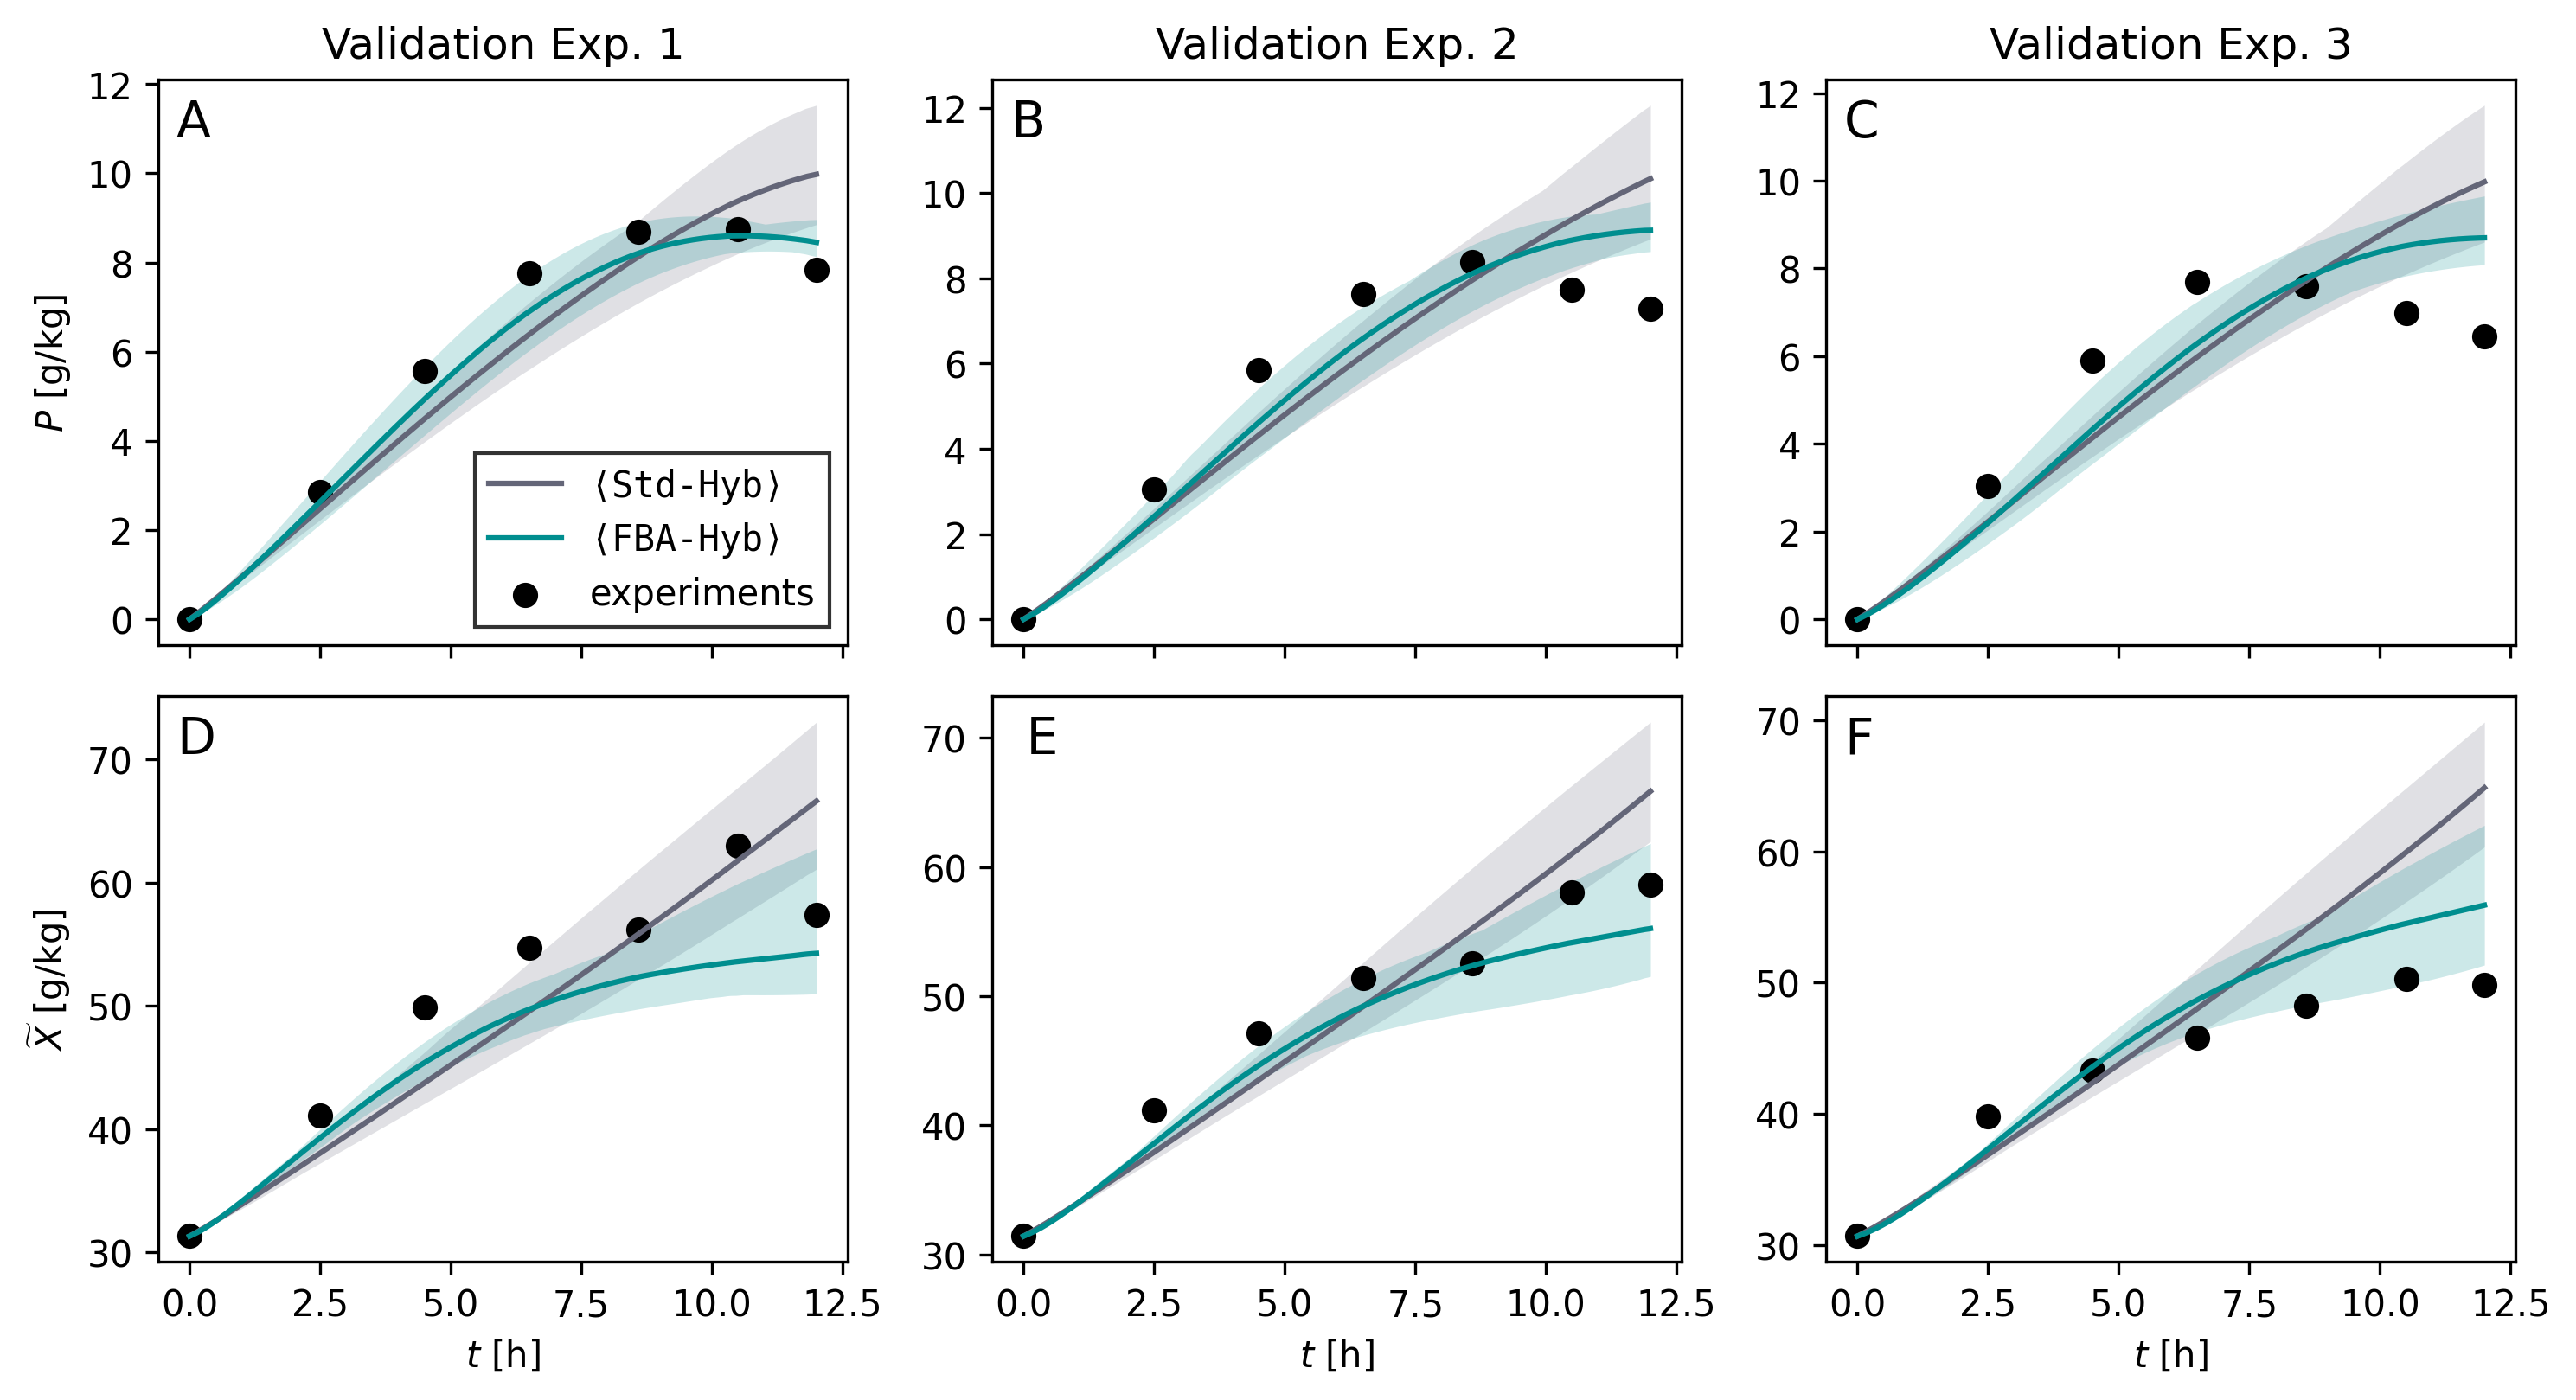

In [9]:
labels = {"G":"G [g/kg]", "P":r"$P$ [g/kg]", "X":r"$\widetilde{X}$ [g/kg]", "V":"V [kg]"}
fig, axes = plt.subplots(2, 3, dpi=300, figsize=(10, 5.5), sharex=True)
for row, (var, j) in enumerate([("P",1), ("X",2)]):
    for p in range(3):
        ax = axes[row, p]
        for v, lab in versions.items():
            c = AF.get_color_from_fba_type(AF.get_fba_type(v))
            M = SMTH_MEMB[v][:, p, :, j]
            ax.fill_between(TT_SMTH[p], M.min(0), M.max(0), color=c, alpha=.2, lw=0)
            ax.plot(TT_SMTH[p], SMTH[v]["Y"][p, :, j], "-", color=c, lw=1.5, label=f"⟨{lab}⟩")

        ax.scatter(tt[p], Y_TRUE_VAL[p, :, j], color="k", marker="o", label="experiments")
        if row == 0: ax.set_title(f"Validation Exp. {VAL_names[p][-1]}")
        if p == 0: ax.set_ylabel(labels[var])
        if row == 1: ax.set_xlabel(r"$t$ [h]")

import matplotlib.transforms as mtransforms
for name, ax in zip(['A','B','C','D',' E','F'],axes.flatten()):
    trans = mtransforms.ScaledTranslation(5/72, -5/72, fig.dpi_scale_trans)
    ax.text(0.0, 1.0, name, transform=ax.transAxes + trans,
    fontsize=14, verticalalignment='top', fontfamily='sans',
    bbox=dict(facecolor='none', edgecolor='none', pad=3.0))


leg = axes[0,0].legend(fancybox=False, edgecolor="k")
for txt in leg.get_texts():
    if txt.get_text().startswith("⟨"):
        txt.set_fontfamily("monospace")
plt.tight_layout()
plt.show()

# Figure 2: Validation results

In [10]:
importlib.reload(AF)
importlib.reload(UF)

versions = []
not_found = []
for nr in [141,142,143,144,145,146]:
    nr = f"{nr:02.0f}"
    for let in ["A","B","B/ANN2SR_03"]:
        version = f"MPM_{nr}{let}"
        id = "_sc"
        filepath = f"{REPO_ROOT}/prol_model_data/{version}/analysis{id}.pkl"
        if not os.path.isfile(filepath):
            # print(version, "not found")
            not_found.append(version)
        else:
            versions.append(version)

print("NOT FOUND:",not_found)
metrics = ["R2","NMAE"]
_ = AF.NEW_compare_versions(versions,
                            # last_model=False,     # bool, default = True
                            # equal_comparison=False, # bool, default = True
                            metrics=metrics,
                            )
METRIC_values, labels = _


NOT FOUND: []
Last Model       : True
Equal Comparison : True
--- R2   ---


                          | avg(GPX) | avg(PX)  | G        | P        | X        | V        | P/X      | 
---------------------------------------------------------------------------------------------------------
                 MPM_141A |   0.6472 |   0.5452 |   0.8510 |   0.5879 |   0.5026 |   0.9973 |   0.3703 |  NO
                 MPM_141B |   0.7200 |   0.6392 |   0.8817 |   0.6330 |   0.6454 |   0.9811 |   0.3960 |  NN
       MPM_141B/ANN2SR_03 |   0.7621 |   0.6878 |   0.9108 |   0.6507 |   0.7249 |   0.9845 |   0.4407 |  SR


                 MPM_142A |   0.4947 |   0.4558 |   0.5726 |   0.4414 |   0.4702 |   0.9961 |   0.2768 |  NO
                 MPM_142B |   0.7616 |   0.7015 |   0.8819 |   0.7288 |   0.6742 |   0.9839 |   0.4674 |  NN


       MPM_142B/ANN2SR_03 |   0.7569 |   0.6963 |   0.8782 |   0.7202 |   0.6724 |   0.9842 |   0.4719 |  SR
                 MPM_143A |   0.5683 |   0.4432 |   0.8185 |   0.5659 |   0.3205 |   0.9952 |   0.5455 |  NO
                 MPM_143B |   0.7171 |   0.6590 |   0.8334 |   0.6769 |   0.6411 |   0.9969 |   0.3921 |  NN


       MPM_143B/ANN2SR_03 |   0.7339 |   0.6728 |   0.8560 |   0.6642 |   0.6815 |   0.9971 |   0.4099 |  SR
                 MPM_144A |   0.6693 |   0.5770 |   0.8538 |   0.6800 |   0.4740 |   0.9982 |   0.4623 |  NO


...

                 MPM_145B |   0.2757 |   0.2043 |   0.4185 |   0.3094 |   0.0992 |   0.0100 |   0.4006 |  NN


       MPM_145B/ANN2SR_03 |   0.2928 |   0.2171 |   0.4442 |   0.3308 |   0.1033 |   0.0101 |   0.4062 |  SR


                 MPM_146A |   0.3274 |   0.2633 |   0.4556 |   0.3810 |   0.1456 |   0.0110 |   0.3721 |  NO


                 MPM_146B |   0.2693 |   0.2075 |   0.3928 |   0.3190 |   0.0961 |   0.0099 |   0.4035 |  NN


       MPM_146B/ANN2SR_03 |   0.2614 |   0.1987 |   0.3870 |   0.3038 |   0.0936 |   0.0098 |   0.3830 |  SR


In [11]:
# test-set R2 (pooled over VAL_R1-3, ensemble mean); index 3 = P, 4 = X
TEST_R2 = {}
for v in ["MPM_144A", "MPM_144B"]:
    stats, _ = AF.NEW_print_stats((Y_TRUE_VAL, PRED[v]), v, verbose=False, metric="R2")
    TEST_R2[v] = stats

# OptFed predictions for the test set, interpolated to the measurement times
opt = pd.read_csv(f"{REPO_ROOT.parent}/optfed_validation.csv")
P_OPT = np.zeros((3, tt.shape[1], 2))          # [:,:,0]=P, [:,:,1]=X
for p, name in enumerate(["P1", "P2", "P3"]):  # = VAL_R1..R3 = reference / intermediate / optimal
    d = opt[opt.process == name].sort_values("t", kind="stable")
    P_OPT[p, :, 0] = np.interp(np.asarray(tt[p]), d.t, d.P)
    P_OPT[p, :, 1] = np.interp(np.asarray(tt[p]), d.t, d.X)

# sanity check: X(t=0) should be ~31.3 / 31.4 / 30.7 for P1 / P2 / P3
print("X0 measured:", np.asarray(Y_TRUE_VAL[:, 0, 2]).round(1), " optfed:", P_OPT[:, 0, 1].round(1))

TEST_R2["OPTFED"] = (UF.R2(np.asarray(Y_TRUE_VAL[:, :, 1]).flatten(), P_OPT[:, :, 0].flatten()),
                     UF.R2(np.asarray(Y_TRUE_VAL[:, :, 2]).flatten(), P_OPT[:, :, 1].flatten()))
print("OptFed test R2  P: %.2f  X: %.2f" % TEST_R2["OPTFED"])


X0 measured: [31.3 31.4 30.7]  optfed: [31.3 31.4 30.7]
OptFed test R2  P: 0.88  X: 0.87


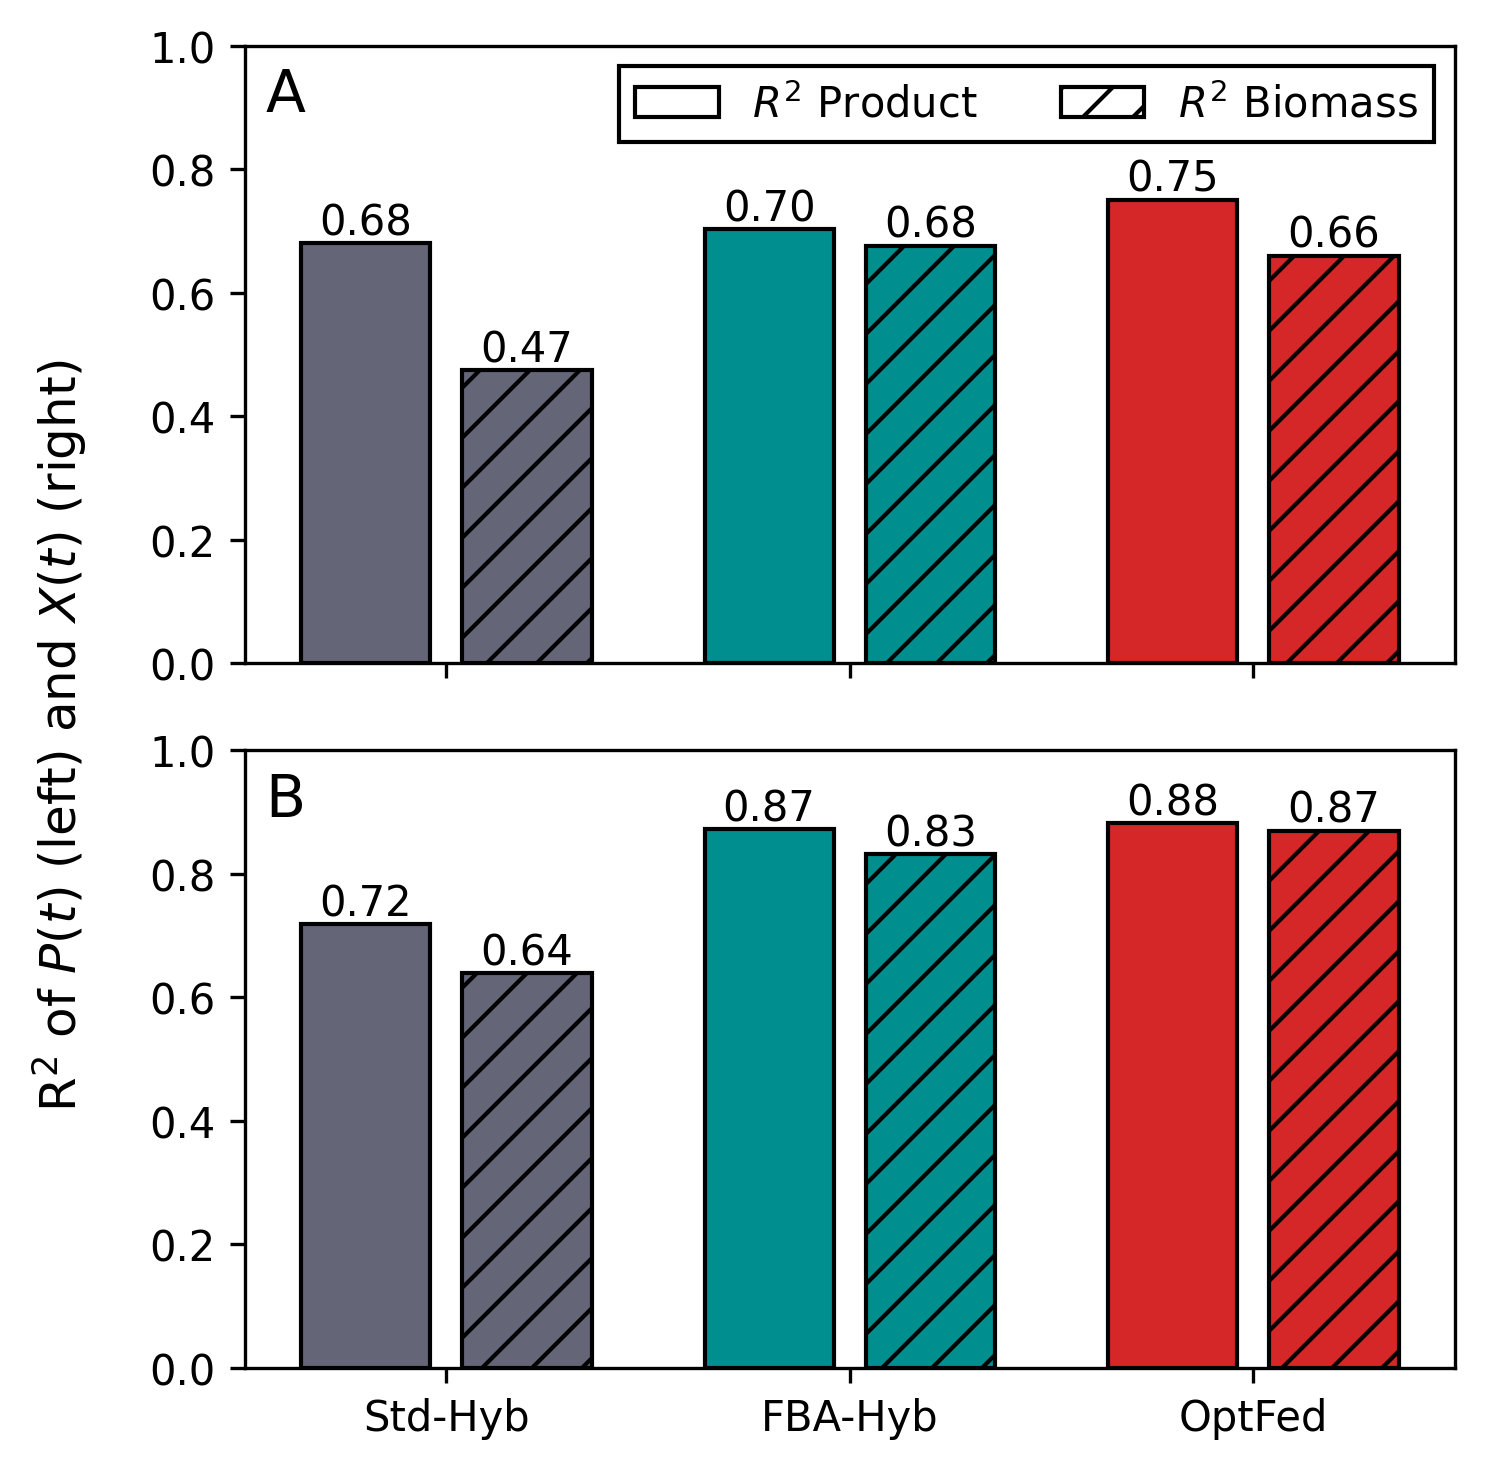

In [12]:
std_version = "MPM_144A"
fba_version = "MPM_144B"

def draw_group(ax, l0, lP, lX, color):
    ax.bar(l0,   lP, color=color, edgecolor="k")
    ax.bar(l0+1, lX, color=color, edgecolor="k", hatch="//")
    ax.text(l0,   lP, f"{lP:.2f}", ha="center", va="bottom")
    ax.text(l0+1, lX, f"{lX:.2f}", ha="center", va="bottom")

fig, (ax_cv, ax_te) = plt.subplots(2, 1, dpi=300, figsize=(5, 5), sharex=True)

# --- top: cross-validation ---
draw_group(ax_cv, 5,   .75, .66, "C3")   # OptFed
draw_group(ax_cv, 0,   METRIC_values[0][std_version][3], METRIC_values[0][std_version][4], AF.get_color_from_fba_type("NO"))
draw_group(ax_cv, 2.5, METRIC_values[0][fba_version][3], METRIC_values[0][fba_version][4], AF.get_color_from_fba_type("NN"))
# ax_cv.set_title("Cross-validation")

# --- bottom: test set ---
draw_group(ax_te, 0,   float(TEST_R2[std_version][3]), float(TEST_R2[std_version][4]), AF.get_color_from_fba_type("NO"))
draw_group(ax_te, 2.5, float(TEST_R2[fba_version][3]), float(TEST_R2[fba_version][4]), AF.get_color_from_fba_type("NN"))
draw_group(ax_te, 5,   float(TEST_R2["OPTFED"][0]), float(TEST_R2["OPTFED"][1]), "C3")   # OptFed
# ax_te.set_title("Test set")

# legend entries (off-screen dummy bars) on the top panel
ax_cv.bar(-10, .05, color="w", edgecolor="k", label="$R^2$ Product")
ax_cv.bar(-10, .05, color="w", edgecolor="k", label="$R^2$ Biomass", hatch="//")
ax_cv.legend(fancybox=False, edgecolor="k", loc="upper right", framealpha= 1, ncols=2)

for ax in (ax_cv, ax_te):
    ax.set_ylim(0, 1)
    ax.set_xlim(-.75, 6.75)
fig.supylabel("R$^2$ of $P(t)$ (left) and $X(t)$ (right)")
ax_te.set_xticks([.5, 3, 5.5], ["Std-Hyb", "FBA-Hyb", "OptFed"])

import matplotlib.transforms as mtransforms
for name, ax in zip(['A','B'], (ax_cv, ax_te)):
    trans = mtransforms.ScaledTranslation(5/72, -5/72, fig.dpi_scale_trans)
    ax.text(0.0, 1.0, name, transform=ax.transAxes + trans,
    fontsize=14, verticalalignment='top', fontfamily='sans',
    bbox=dict(facecolor='none', edgecolor='none', pad=3.0))

plt.tight_layout()
plt.show()